# Prédiction de la Popularité des Titres Spotify
**Formation :** Master 1 SSD — Université Grenoble Alpes (UGA)  
**Binôme :** Ramez Dahouathi & Noé Desanlis  

**Objectif :** Ce projet vise à prédire le score de popularité continu ($[0, 100]$) de titres Spotify inédits à partir de leurs caractéristiques acoustiques, de leur structure musicale et de leurs métadonnées. Notre approche intègre le traitement des valeurs manquantes et l'encodage catégoriel (*One-Hot Encoding*) des genres, avant d'entraîner et d'optimiser des modèles de régression par arbres (`DecisionTreeRegressor` et `RandomForestRegressor`) évalués selon la racine de l'erreur quadratique moyenne (RMSE).

In [2]:
# Les libreries necessiaires pour le projet
import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.metrics import root_mean_squared_error


from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

In [3]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

print(f"Training Set Shape: {train_df.shape}")
print(f"Testing Set Shape:  {test_df.shape}")

print("\n--- Training Data Preview ---")
display(train_df.head())

print("\n--- Testing Data Preview ---")
display(test_df.head())

Training Set Shape: (91200, 21)
Testing Set Shape:  (22800, 20)

--- Training Data Preview ---


,id,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,6KwkVtXm8OUp2XffN5k7lY,Hillsong Worship,No Other Name,No Other Name,50,440247,False,0.369,0.598,7,-6.984,1,0.0304,0.00511,0.000000,0.176,0.0466,148.014,4,world-music
1,1,2dp5I5MJ8bQQHDoFaNRFtX,Internal Rot,Grieving Birth,Failed Organum,11,93933,False,0.171,0.997,7,-3.586,1,0.1180,0.00521,0.801000,0.420,0.0294,122.223,4,grindcore
2,2,5avw06usmFkFrPjX8NxC40,Zhoobin Askarieh;Ali Sasha,Noise A Noise 20.4-1,"Save the Trees, Pt. 1",0,213578,False,0.173,0.803,9,-10.071,0,0.1440,0.61300,0.001910,0.195,0.0887,75.564,3,iranian
3,3,75hT0hvlESnDJstem0JgyR,Bryan Adams,All I Want For Christmas Is You,Merry Christmas,0,151387,False,0.683,0.511,6,-5.598,1,0.0279,0.40600,0.000197,0.111,0.5980,109.991,3,rock
4,4,4bY2oZGA5Br3pTE1Jd1IfY,Nogizaka46,バレッタ TypeD,月の大きさ,57,236293,False,0.555,0.941,9,-3.294,0,0.0481,0.48400,0.000000,0.266,0.8130,92.487,4,j-idol



--- Testing Data Preview ---


,id,track_id,artists,album_name,track_name,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,91200,3BpiSlF0Z4CZQxcObv7erK,Jay Chou,最偉大的作品,我是如此相信,265013,False,0.490,0.538,0,-8.888,1,0.0291,0.14500,0.000036,0.1020,0.107,137.968,4,mandopop
1,91201,0NIpFxO2TIPUEjNgczHrsP,Сергей Зыков,Первый снег,"Улица, улица",208613,False,0.495,0.372,7,-10.438,1,0.0435,0.97100,0.005260,0.0455,0.827,135.657,3,romance
2,91202,5fy4vfEtv6lzqLx2Mt7stF,Pet Shop Boys,Actually: Further Listening 1987 - 1988 (2018 ...,It's a Sin - 2018 Remaster,299253,False,0.544,0.860,0,-6.151,0,0.0489,0.20600,0.001080,0.2130,0.284,127.129,4,synth-pop
3,91203,1TvNcWY7WwPLQINhimxycA,Jimmy Eat World,Bleed American,Hear You Me,284373,False,0.465,0.517,4,-6.189,1,0.0284,0.00854,0.040300,0.2090,0.137,136.176,3,emo
4,91204,0WP2SQI2kVgHM7FHPQ97Fo,Lasse Stefanz,Mi Vida Loca,Cheerio,230160,False,0.657,0.823,7,-6.884,1,0.0303,0.04820,0.001200,0.1820,0.742,134.075,4,swedish


## 1. Prétraitement et Nettoyage des Données
Nous analysons d'abord la proportion de valeurs manquantes dans les ensembles d'entraînement et de test, puis nous supprimons les métadonnées textuelles à haute cardinalité (`track_id`, `artists`, `album_name`, `track_name`) non directement exploitables par les arbres de décision.

In [4]:
def check_missing_data(df, dataset_name):
    missing_count = df.isnull().sum()
    missing_pct = (missing_count / len(df)) * 100
    missing_table = pd.DataFrame({'Missing Count': missing_count,'Percentage (%)': missing_pct.round(4)})
    missing_table = missing_table[missing_table['Missing Count'] > 0]
    
    print(f"--- Missing Values in {dataset_name} (Total rows: {len(df)}) ---")
    if missing_table.empty:
        print("No missing values found!\n")
    else:
        display(missing_table.sort_values(by='Percentage (%)', ascending=False))

check_missing_data(train_df, "Train Set")
check_missing_data(test_df, "Test Set")

--- Missing Values in Train Set (Total rows: 91200) ---
No missing values found!

--- Missing Values in Test Set (Total rows: 22800) ---
No missing values found!



Eh bien, c’est tout à fait normal, car il s’agit d’un défi Kaggle ; notre jeu de données ne devrait donc contenir aucune valeur nulle.

In [5]:
# on efface les colonnes nécessaires pour le modèle
cols_to_drop = ['id','track_id', 'artists', 'album_name', 'track_name']
test_ids = test_df['id'].copy()
train_clean = train_df.drop(columns= cols_to_drop)
test_clean = test_df.drop(columns= cols_to_drop)

# on convertis le Boulean en int pour le model
train_clean['explicit'] = train_clean['explicit'].astype(int)
test_clean['explicit'] = test_clean['explicit'].astype(int)

print(f"Cleaned Train : {train_clean.shape}")
print(f"Cleaned Test :  {test_clean.shape}")
display(train_clean.head(3))

Cleaned Train : (91200, 16)
Cleaned Test :  (22800, 15)


,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,50,440247,0,0.369,0.598,7,-6.984,1,0.0304,0.00511,0.00000,0.176,0.0466,148.014,4,world-music
1,11,93933,0,0.171,0.997,7,-3.586,1,0.1180,0.00521,0.80100,0.420,0.0294,122.223,4,grindcore
2,0,213578,0,0.173,0.803,9,-10.071,0,0.1440,0.61300,0.00191,0.195,0.0887,75.564,3,iranian


## 2. Analyse Exploratoire des Données (EDA)
L'analyse se concentre sur la distribution de la variable cible (`popularity`) afin d'identifier d'éventuelles asymétries ou valeurs nulles massives, ainsi que sur la matrice de corrélation des caractéristiques audio numériques.

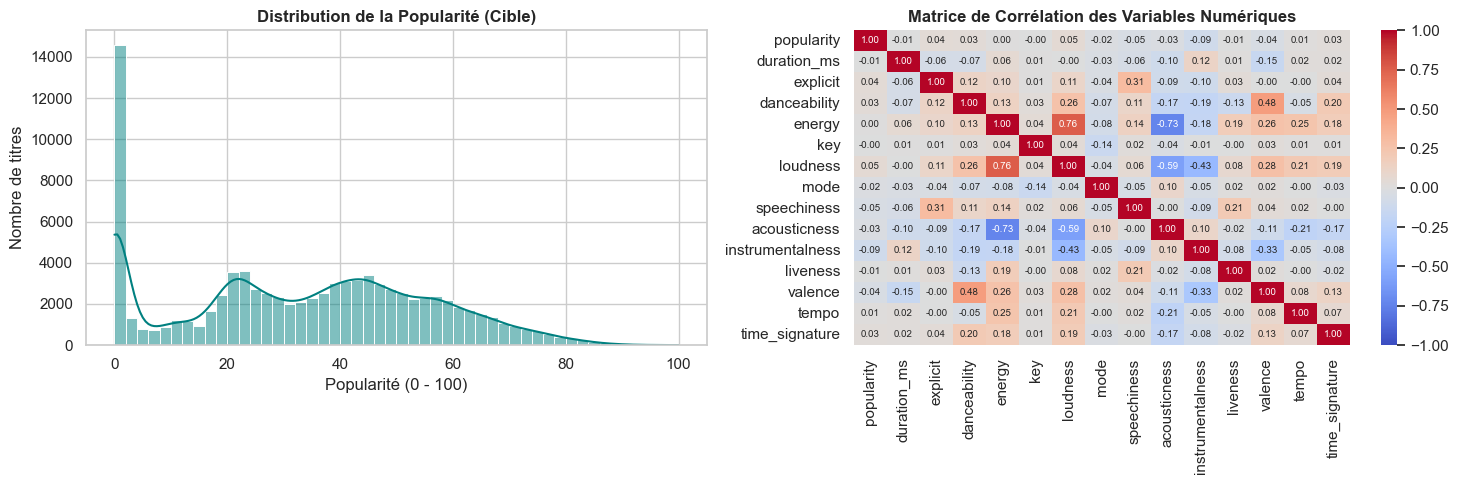

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Distribution of the Target Variable (Popularity)
sns.histplot(train_clean['popularity'], bins=50, kde=True, ax=axes[0], color='teal')
axes[0].set_title("Distribution de la Popularité (Cible)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Popularité (0 - 100)")
axes[0].set_ylabel("Nombre de titres")

numeric_cols = train_clean.select_dtypes(include=[np.number]).columns
corr_matrix = train_clean[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7},ax=axes[1])
axes[1].set_title("Matrice de Corrélation des Variables Numériques", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

the correlation matrix is not looking good. It proves that a simple linear model (like Linear Regression) would completely fail here, which mathematically justifies using non-linear tree-based models.
Strong Collinearity Between Features: energy and loudness are strongly positively correlated ($0.76$), while energy and acousticness ($-0.73$) as well as loudness and acousticness ($-0.59$) are strongly negatively correlated. Decision trees handle collinearity well, though it slightly dilutes feature importance in Random Forests.  

## 3. Ingénierie des Variables et Encodage Catégoriel
Aucune valeur manquante n'étant présente, nous préparons les matrices finales en trois étapes :
1. **Regroupement binaire (`is_4_4_time`) :** La signature rythmique `time_signature` étant dominée à ~90% par la mesure standard $\frac{4}{4}$ (`4`), nous la simplifions en une variable indicatrice binaire (`1` si signature $= 4$, `0` sinon).
2. **One-Hot Encoding :** Application d'un encodage disjonctif complet sur les variables nominales `track_genre` (114 catégories) et `key` (12 tonalités musicales).

In [7]:
# 1. Separate target variable (y_train) and raw feature sets
y_train = train_clean['popularity'].copy()
X_train_fe = train_clean.drop(columns=['popularity']).copy()
X_test_fe = test_clean.copy()

# 2. Binary Grouping for time_signature: 1 if 4/4 time ('4'), 0 otherwise
X_train_fe['is_4_4_time'] = (X_train_fe['time_signature'].astype(str) == '4').astype(int)
X_test_fe['is_4_4_time'] = (X_test_fe['time_signature'].astype(str) == '4').astype(int)

# Drop the original time_signature column
X_train_fe.drop(columns=['time_signature'], inplace=True)
X_test_fe.drop(columns=['time_signature'], inplace=True)

# Quick verification of the binary grouping proportion
print("Proportion de titres en mesure 4/4 (Train) :")
print(X_train_fe['is_4_4_time'].value_counts(normalize=True).round(4))

Proportion de titres en mesure 4/4 (Train) :
is_4_4_time
1    0.8934
0    0.1066
Name: proportion, dtype: float64


In [ ]:
# 3. Ensure 'key' and 'track_genre' are treated as strings for clean column naming
categorical_features = ['track_genre', 'key']
for col in categorical_features:
    X_train_fe[col] = X_train_fe[col].astype(str)
    X_test_fe[col] = X_test_fe[col].astype(str)

# Identify all remaining numerical & binary features (including 'is_4_4_time')
numerical_features = [col for col in X_train_fe.columns if col not in categorical_features]

# 4. Configure ColumnTransformer for One-Hot Encoding
preprocessor = ColumnTransformer(transformers=[('num', 'passthrough', numerical_features),('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)])

# 5. Fit strictly on Train and transform both Train and Test
X_train_array = preprocessor.fit_transform(X_train_fe)
X_test_array = preprocessor.transform(X_test_fe)

# Reconstruct DataFrames with explicit feature names (crucial for Feature Importance plots)
ohe_feature_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features))
all_feature_names = numerical_features + ohe_feature_names

X_train = pd.DataFrame(X_train_array, columns=all_feature_names, index=X_train_fe.index)
X_test = pd.DataFrame(X_test_array, columns=all_feature_names, index=X_test_fe.index)

print(f"y_train shape : {y_train.shape}")
print(f"X_train shape : {X_train.shape} (12 num/bin + 114 genres + 12 keys = 138 variables)")
print(f"X_test shape  : {X_test.shape}")
display(X_train.iloc[:3, :15])

y_train shape : (91200,)
X_train shape : (91200, 139) (12 num/bin + 114 genres + 12 keys = 138 variables)
X_test shape  : (22800, 139)


,duration_ms,explicit,danceability,energy,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,is_4_4_time,track_genre_acoustic,track_genre_afrobeat
0,440247.0,0.0,0.369,0.598,-6.984,1.0,0.0304,0.00511,0.00000,0.176,0.0466,148.014,1.0,0.0,0.0
1,93933.0,0.0,0.171,0.997,-3.586,1.0,0.1180,0.00521,0.80100,0.420,0.0294,122.223,1.0,0.0,0.0
2,213578.0,0.0,0.173,0.803,-10.071,0.0,0.1440,0.61300,0.00191,0.195,0.0887,75.564,0.0,0.0,0.0
